In [2]:
#Shishir Khanal
#Aug 23, 2026
#Cartpole RL Control Agent using Temporal Difference Learning

In [3]:
import numpy as np

In [21]:
class Agent():
    def __init__(self, lr, gamma, n_actions, state_space, eps_start, eps_end, eps_dec):
        self.lr = lr
        self.gamma = eps_start
        self.epsilon = eps_start
        self.eps_end = eps_end
        self.eps_dec = eps_dec
        self.n_actions = n_actions
        self.state_space = state_space
        self.action_space = [i for i in range(self.n_actions)]

        self.Q = {}
        self.init_Q()

    def init_Q(self):
        for state in self.state_space:
            for action in self.action_space:
                self.Q[(state, action)] = 0.0

    def max_action(self, state):
        actions = np.array([self.Q[(state, a)] for a in self.action_space])
        action = np.argmax(actions)
        return action

    def choose_action(self, state):
        if np.random.random() < self.epsilon:
            action = np.random.choice(self.action_space)
        else:
            action = self.max_action(state)
        return action

    def decrement_epsilon(self):
        self.epsilon = self.epsilon - self.eps_dec if self.epsilon > self.eps_end else self.eps_end #Linear decrement

    def learn(self, state, action, reward, state_):
        a_max = self.max_action(state_)
        self.Q[(state, action)] = self.Q[(state, action)] + self.lr * (reward + self.gamma * self.Q[(state_, a_max)] - self.Q[(state, action)])

In [22]:
import gym
import matplotlib.pyplot as plt

In [23]:
class CartPlotStateDigitizer():
    def __init__(self, bounds=(2.4, 4, 0.209, 4), n_bins=10):
        self.position_space = np.linspace(-1*bounds[0], bounds[0], n_bins)
        self.velocity_space = np.linspace(-1*bounds[1], bounds[1], n_bins)
        self.pole_angle_space = np.linspace(-1*bounds[2], bounds[2], n_bins)
        self.pole_velocity_space = np.linspace(-1*bounds[3], bounds[3], n_bins)
        self.states = self.get_state_space()

    def get_state_space(self):
        states = []
        for i in range(len(self.position_space)+1):
            for j in range(len(self.velocity_space)+1):
                for k in range(len(self.pole_angle_space)+1):
                    for l in range(len(self.pole_velocity_space)+1):
                        states.append((i, j, k, l))

        return states

    def digitize(self, observation):
        x, x_dot, theta, theta_dot = observation
        cart_x = int(np.digitize(x, self.position_space))
        cart_xdot = int(np.digitize(x_dot, self.velocity_space))
        pole_theta = int(np.digitize(theta, self.pole_angle_space))
        pole_thetadot = int(np.digitize(theta_dot, self.pole_velocity_space))

        return(cart_x, cart_xdot, pole_theta, pole_thetadot)

In [24]:
def plot_learning_curve(scores, x):
    running_avg = np.zeros(len(scores))
    for i in range(len(running_avg)):
        running_avg[i] = np.mean(scores[max(0, i-100):(i+1)])

    plt.plot(x, running_avg)
    plt.title('Running Avg of last 100 scores')
    plt.show()

episode 0 score 23.0 epsilon 1.00
episode 5000 score 48.0 epsilon 0.80
episode 10000 score 40.0 epsilon 0.60
episode 15000 score 126.0 epsilon 0.40
episode 20000 score 201.0 epsilon 0.20
episode 25000 score 500.0 epsilon 0.01
episode 30000 score 500.0 epsilon 0.01
episode 35000 score 500.0 epsilon 0.01
episode 40000 score 500.0 epsilon 0.01
episode 45000 score 500.0 epsilon 0.01


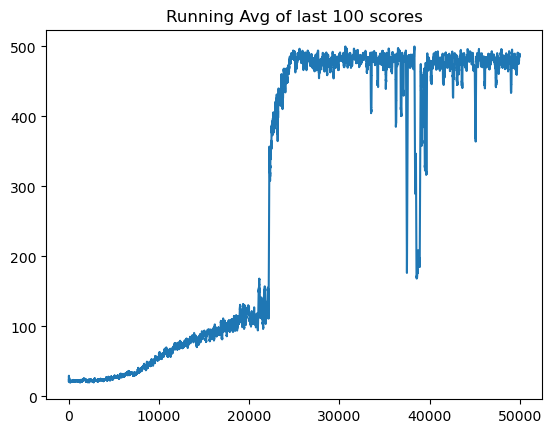

In [26]:
if __name__ == '__main__':
    env = gym.make('CartPole-v1')
    n_games = 50000
    eps_dec = 2 / n_games
    digitizer = CartPlotStateDigitizer()
    agent = Agent(lr=0.01, gamma=0.99, n_actions=2, eps_start=1.0, eps_end=0.01, eps_dec=eps_dec, state_space=digitizer.states)
    scores = []
    for i in range(n_games):
        observation, info = env.reset()
        done = False
        score = 0
        state = digitizer.digitize(observation)
        while not done:
            action = agent.choose_action(state)
            observation_, reward, terminated, truncated, info = env.step(action)
            done = terminated or truncated
            state_ = digitizer.digitize(observation_)
            agent.learn(state, action, reward, state_)
            state = state_
            score += reward

        if i % 5000 == 0:
            print('episode', i , 'score %.1f' % score, 'epsilon %.2f' % agent.epsilon)

        agent.decrement_epsilon()
        scores.append(score)

    x = [i+1 for i in range(n_games)]
    plot_learning_curve(scores, x)